# E-commerce Sales Data Analysis

## Project Objective
To analyze e-commerce sales, customer behavior, product performance, and profitability using SQL and Python.

## Tools Used
- MySQL
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Approach
1. Understand the dataset
2. Validate data quality
3. Define 10 business questions
4. Analyze data using SQL
5. Visualize findings using Python
6. Document insights and recommendations

In [3]:
import pandas as pd
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="****",
    database="ecommerce_db"
)

query = """
SELECT *
FROM ecommerce_sales_customer_analytics_150k;
"""

df = pd.read_sql(query, conn)

conn.close()

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


C:\Users\surbh\AppData\Local\Temp\ipykernel_33724\3970942079.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


Data loaded successfully!
Dataset shape: (138116, 46)


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.4,588.33,345.04,36.5,12459.68,1,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.0600000000002,320.83,9.0,2018.41,2031.88,-22.47000000000001,-1.11,13032.48,1,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.3,29.79,13.05,468.35,257.73,197.57,42.18,6159.4400000000005,1,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84000000000003,247.83,45.35,5638.3,1,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.1,1,8


In [4]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])


Missing values in each column:


delivery_days               24557
estimated_delivery_days     24557
return_status              128654
return_reason              128654
customer_rating             24557
review_sentiment            24557
customer_review             24557
campaign_name               83233
coupon_code                110502
dtype: int64

# Missing Value Percentage

In [5]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report.round(2))


,Missing_Count,Missing_Percentage
return_status,128654,93.15
return_reason,128654,93.15
coupon_code,110502,80.01
campaign_name,83233,60.26
delivery_days,24557,17.78
estimated_delivery_days,24557,17.78
customer_rating,24557,17.78
review_sentiment,24557,17.78
customer_review,24557,17.78


# Check Duplicate Records

In [6]:
duplicate_count = df.duplicated().sum()

print("Total exact duplicate rows:", duplicate_count)


Total exact duplicate rows: 0


In [7]:
print("Total rows:", len(df))
print("Unique order IDs:", df["order_id"].nunique())
print("Rows with repeated order IDs:",
      df["order_id"].duplicated().sum())

Total rows: 138116
Unique order IDs: 138116
Rows with repeated order IDs: 0


# Observation:
# The main e-commerce dataset contains 138,116 rows and 138,116 unique order IDs. No exact duplicate rows or repeated order IDs were found in this table.

# Check Data Types

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   order_id                  138116 non-null  object
 1   order_date                138116 non-null  object
 2   order_time                138116 non-null  object
 3   order_status              138116 non-null  object
 4   sales_channel             138116 non-null  object
 5   customer_id               138116 non-null  object
 6   customer_name             138116 non-null  object
 7   customer_age              138116 non-null  object
 8   gender                    138116 non-null  object
 9   customer_segment          138116 non-null  object
 10  customer_type             138116 non-null  object
 11  customer_city             138116 non-null  object
 12  customer_state            138116 non-null  object
 13  customer_country          138116 non-null  object
 14  regi

# Inspect Important Columns

In [9]:
columns_to_check = [
    "order_date",
    "customer_age",
    "quantity",
    "gross_sales",
    "net_sales",
    "profit",
    "profit_margin_percentage",
    "is_repeat_customer"
]

for column in columns_to_check:
    print(f"\nColumn: {column}")
    print(df[column].head(5).tolist())



Column: order_date
['2023-11-06', '2025-12-24', '2021-07-05', '2023-01-21', '2022-05-13']

Column: customer_age
['55', '26', '69', '65', '34']

Column: quantity
['5', '8', '5', '2', '6']

Column: gross_sales
['1350.19', '3144.64', '522.81', '544.62', '2474.52']

Column: net_sales
['945.4', '2018.41', '468.35', '546.52', '2785.27']

Column: profit
['345.04', '-22.47000000000001', '197.57', '247.83', '1530.36']

Column: profit_margin_percentage
['36.5', '-1.11', '42.18', '45.35', '54.94']

Column: is_repeat_customer
['1', '1', '1', '1', '1']


# Convert Data Types

In [10]:

# Create a working copy
df_clean = df.copy()

# Convert order_date to date format
df_clean["order_date"] = pd.to_datetime(
    df_clean["order_date"],
    errors="coerce"
)

# Convert numeric columns
numeric_columns = [
    "customer_age",
    "quantity",
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "profit",
    "profit_margin_percentage",
    "customer_lifetime_value",
    "customer_order_count",
    "delivery_days",
    "estimated_delivery_days",
    "customer_rating",
    "loyalty_points_earned",
    "loyalty_points_redeemed"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

print("Data type conversion completed!")
df_clean[[
    "order_date",
    "customer_age",
    "quantity",
    "net_sales",
    "profit"
]].info()


Data type conversion completed!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_date    138116 non-null  datetime64[ns]
 1   customer_age  138116 non-null  int64         
 2   quantity      138116 non-null  int64         
 3   net_sales     138116 non-null  float64       
 4   profit        138116 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2)
memory usage: 5.3 MB


# Validate Important Values

In [11]:
print("Order date range:")
print("First date:", df_clean["order_date"].min())
print("Last date:", df_clean["order_date"].max())

print("\nCustomer age range:")
print("Minimum age:", df_clean["customer_age"].min())
print("Maximum age:", df_clean["customer_age"].max())

print("\nQuantity range:")
print("Minimum quantity:", df_clean["quantity"].min())
print("Maximum quantity:", df_clean["quantity"].max())

print("\nNegative profit orders:",
      (df_clean["profit"] < 0).sum())

print("Zero or negative quantity rows:",
      (df_clean["quantity"] <= 0).sum())


Order date range:
First date: 2021-01-01 00:00:00
Last date: 2025-12-31 00:00:00

Customer age range:
Minimum age: 18
Maximum age: 74

Quantity range:
Minimum quantity: 1
Maximum quantity: 24

Negative profit orders: 1296
Zero or negative quantity rows: 0


# Explore Order Status and Sales Channels

In [12]:
print("Order Status Counts:")
display(df_clean["order_status"].value_counts(dropna=False))

print("\nSales Channel Counts:")
display(df_clean["sales_channel"].value_counts(dropna=False))

print("\nPayment Status Counts:")
display(df_clean["payment_status"].value_counts(dropna=False))


Order Status Counts:


order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64


Sales Channel Counts:


sales_channel
Mobile App      55318
Website         48237
Marketplace     20698
Social Media    13863
Name: count, dtype: int64


Payment Status Counts:


payment_status
Paid        104250
Pending      13975
Failed       10429
Refunded      9462
Name: count, dtype: int64

### Order, Sales Channel and Payment Status Analysis

**Observations:**
- Completed orders represent the largest order-status category.
- Mobile App is the most frequently used sales channel, followed by Website.
- Paid is the most common payment status.
- Pending and failed payments may require further investigation.
- Order status and payment status represent different business processes and should be analyzed separately.


In [13]:
print("Missing values after data type conversion:")

missing_after_conversion = df_clean.isnull().sum()

display(
    missing_after_conversion[missing_after_conversion > 0]
)


Missing values after data type conversion:


delivery_days               24557
estimated_delivery_days     24557
return_status              128654
return_reason              128654
customer_rating             24557
review_sentiment            24557
customer_review             24557
campaign_name               83233
coupon_code                110502
dtype: int64

# Question 1 — Year-wise Sales Trend

In [16]:
query = """
SELECT
    YEAR(STR_TO_DATE(order_date, '%Y-%m-%d')) AS order_year,
    COUNT(*) AS total_orders,
    ROUND(SUM(CAST(net_sales AS DECIMAL(15,2))), 2) AS total_sales,
    ROUND(SUM(CAST(profit AS DECIMAL(15,2))), 2) AS total_profit
FROM ecommerce_sales_customer_analytics_150k
GROUP BY YEAR(STR_TO_DATE(order_date, '%Y-%m-%d'))
ORDER BY order_year;
"""

yearly_sales = pd.read_sql(query, conn)
display(yearly_sales)


C:\Users\surbh\AppData\Local\Temp\ipykernel_33724\4176435140.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  yearly_sales = pd.read_sql(query, conn)


,order_year,total_orders,total_sales,total_profit
0,2021,27554,35722650.67,15325651.87
1,2022,27564,35327882.62,15167978.69
2,2023,27632,35528143.74,15247695.95
3,2024,27768,35466452.28,15292965.09
4,2025,27598,35089134.43,15112104.16


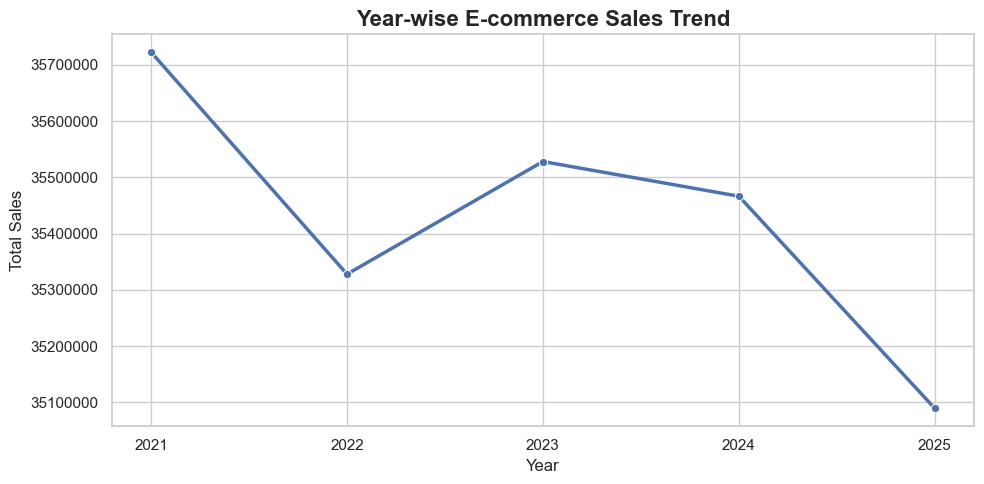

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=yearly_sales,
    x="order_year",
    y="total_sales",
    marker="o",
    linewidth=2.5
)

plt.title("Year-wise E-commerce Sales Trend", fontsize=16, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(yearly_sales["order_year"].astype(int))
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


# observation
**Business Insight:**
Yearly sales remained relatively stable from 2021 to 2025.
The highest sales were recorded in 2021, while 2025 had the lowest sales among these five years. The business should investigate the reasons behind the decline in 2025 sales.


## Question 2: Which Sales Channel Generates the Highest Revenue?

### Business Question
Which sales channel generates the highest revenue: Mobile App, Website, Marketplace, or Social Media?

### Objective
To compare total sales, number of orders, and total profit across different sales channels.

### SQL Analysis
Sales channels are grouped together to calculate total orders, total sales, and total profit. The results are sorted by total sales in descending order.

### Business Insight
To be added after analyzing the SQL results.

In [19]:
query = """
SELECT
    sales_channel,
    COUNT(*) AS total_orders,
    ROUND(SUM(CAST(net_sales AS DECIMAL(15,2))), 2) AS total_sales,
    ROUND(SUM(CAST(profit AS DECIMAL(15,2))), 2) AS total_profit
FROM ecommerce_sales_customer_analytics_150k
GROUP BY sales_channel
ORDER BY total_sales DESC;
"""

channel_sales = pd.read_sql(query, conn)
display(channel_sales)


C:\Users\surbh\AppData\Local\Temp\ipykernel_33724\2705867240.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  channel_sales = pd.read_sql(query, conn)


,sales_channel,total_orders,total_sales,total_profit
0,Mobile App,55318,70834782.53,30451112.22
1,Website,48237,61854736.08,26639693.01
2,Marketplace,20698,26696190.22,11414227.16
3,Social Media,13863,17748554.91,7641363.37


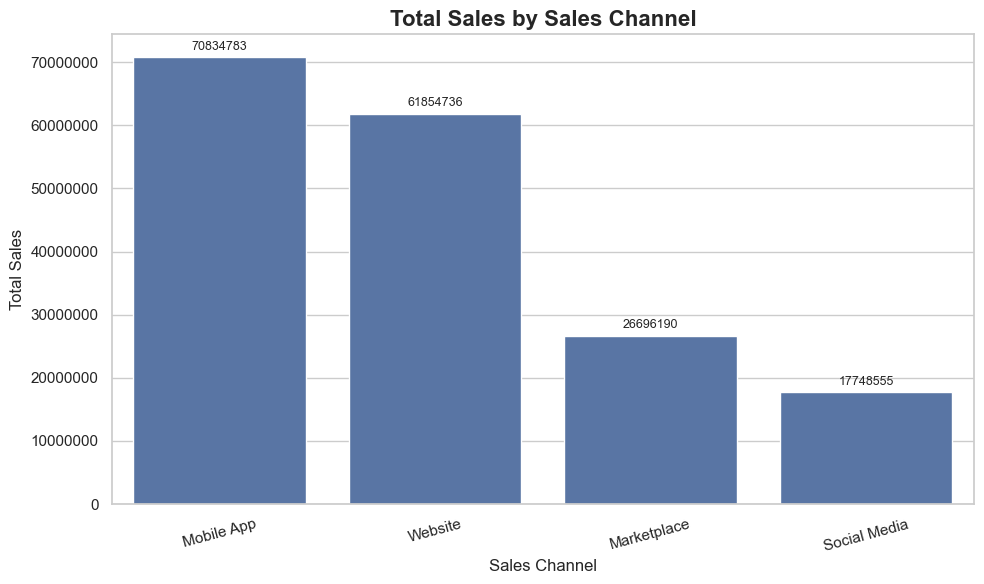

In [20]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=channel_sales,
    x="sales_channel",
    y="total_sales"
)

plt.title("Total Sales by Sales Channel", fontsize=16, fontweight="bold")
plt.xlabel("Sales Channel", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.ticklabel_format(style="plain", axis="y")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Key Findings
- Mobile App generated the highest total sales of approximately 70.83 million.
- Website ranked second, generating approximately 61.85 million in sales.
- Social Media generated the lowest total sales among the four channels.
- Mobile App also recorded the highest total profit.

### Business Recommendation
The business should continue improving the Mobile App shopping experience while investigating opportunities to increase sales through the Website and Social Media channels.

## Question 3: Which Product Categories Generate the Highest Sales?

### Business Question
Which product categories generate the highest sales and profit?

### Objective
To identify the best-performing product categories based on total sales, quantity sold, and profit.

### SQL Analysis
The `order_items` table will be joined with the `product_catalog` table using `product_id`. Sales, quantity, and profit will then be aggregated by product category.

### Key Findings
To be added after analyzing the results.


In [21]:
query = """
SELECT
    p.product_category,
    SUM(oi.quantity) AS total_quantity_sold,
    ROUND(SUM(oi.net_sales), 2) AS total_sales,
    ROUND(SUM(oi.profit), 2) AS total_profit
FROM order_items oi
JOIN product_catalog p
    ON oi.product_id = p.product_id
GROUP BY p.product_category
ORDER BY total_sales DESC;
"""

category_sales = pd.read_sql(query, conn)
display(category_sales)


C:\Users\surbh\AppData\Local\Temp\ipykernel_33724\3397060026.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  category_sales = pd.read_sql(query, conn)


,product_category,total_quantity_sold,total_sales,total_profit
0,Electronics,55784.0,41148162.90,14103982.74
1,Jewelry,48859.0,25561333.78,10391635.32
2,Home Appliances,56281.0,24842478.64,10288878.45
3,Automotive,58046.0,16449898.28,6477194.28
4,Sports & Outdoors,64752.0,15726848.17,7230037.31
5,Home & Kitchen,49682.0,10971629.82,5203824.25
6,Baby & Kids,53945.0,9690605.60,4818148.07
7,Health & Wellness,62054.0,9228068.04,4263304.41
8,Office Supplies,57631.0,8884212.85,4585377.04
9,Fashion,48774.0,7434589.51,3669631.60


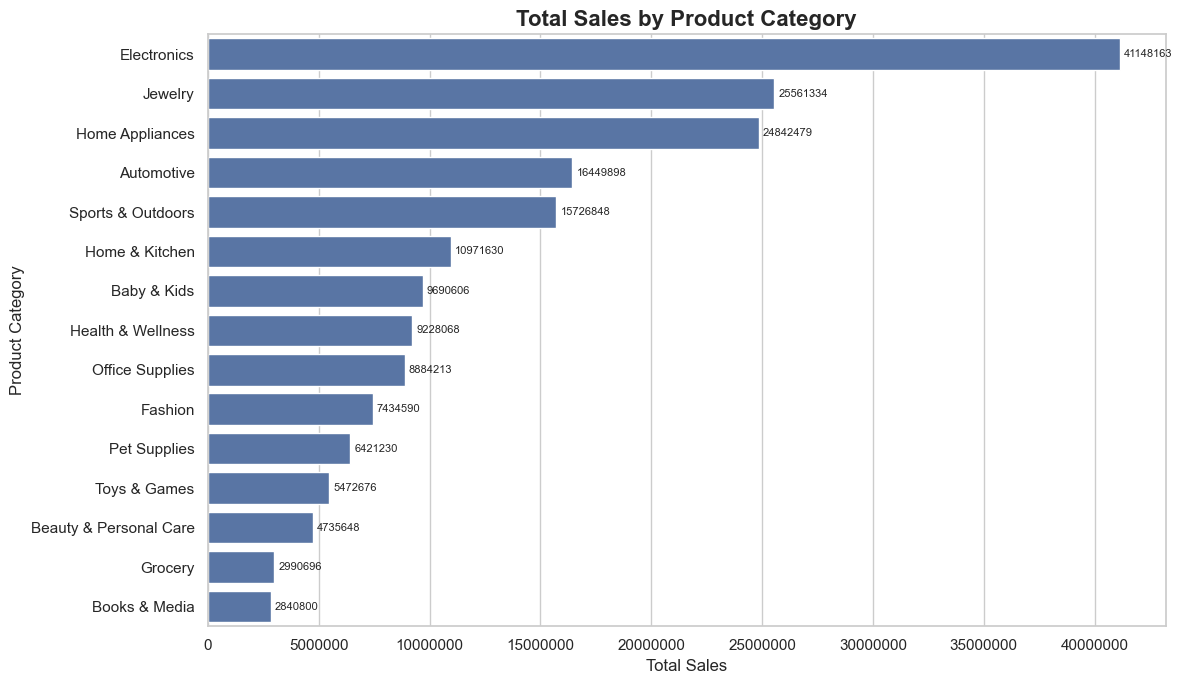

In [22]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=category_sales,
    x="total_sales",
    y="product_category"
)

plt.title(
    "Total Sales by Product Category",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Total Sales", fontsize=12)
plt.ylabel("Product Category", fontsize=12)
plt.ticklabel_format(style="plain", axis="x")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
### Key Findings
- Electronics generated the highest total sales (approximately 41.15 million) and the highest total profit (approximately 14.10 million).
- Sports & Outdoors had the highest quantity sold, with 64,752 units.
- Jewelry ranked second in total sales, generating approximately 25.56 million.
- Books & Media recorded the lowest total sales among the listed categories.

### Business Recommendation
The business should analyze why Electronics performs strongly in sales and profit, maintain sufficient stock for high-demand categories such as Sports & Outdoors, and explore ways to improve sales in lower-performing categories.


In [ ]:
## Question 4: Which Are the Top 10 Best-Selling Products?

### Business Question
Which 10 products have the highest total quantity sold?

### Objective
To identify the most popular products based on total units sold.

### SQL Analysis
The `order_items` table will be joined with the `product_catalog` table to calculate total quantity sold, total sales, and total profit for each product.

### Key Findings
To be added after analyzing the results.


In [23]:
query = """
SELECT
    p.product_id,
    p.product_name,
    p.product_category,
    SUM(oi.quantity) AS total_quantity_sold,
    ROUND(SUM(oi.net_sales), 2) AS total_sales,
    ROUND(SUM(oi.profit), 2) AS total_profit
FROM order_items oi
JOIN product_catalog p
    ON oi.product_id = p.product_id
GROUP BY
    p.product_id,
    p.product_name,
    p.product_category
ORDER BY total_quantity_sold DESC
LIMIT 10;
"""

top_products = pd.read_sql(query, conn)
display(top_products)


C:\Users\surbh\AppData\Local\Temp\ipykernel_33724\1930901367.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_products = pd.read_sql(query, conn)


,product_id,product_name,product_category,total_quantity_sold,total_sales,total_profit
0,PROD-000839,Arm & Hammer Organized maximized software Groo...,Pet Supplies,904.0,135755.74,54928.21
1,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,865.0,223670.71,59879.60
2,PROD-000694,Goodyear Managed clear-thinking secured line T...,Automotive,854.0,369900.26,203403.76
3,PROD-000449,Adidas Public-key homogeneous functionalities ...,Sports & Outdoors,846.0,295343.54,139106.56
4,PROD-000549,HarperCollins Operative multi-tasking budgetar...,Books & Media,844.0,15579.38,6224.93
5,PROD-000878,Graco Networked reciprocal instruction set Dia...,Baby & Kids,841.0,193741.73,127137.57
6,PROD-000928,Evenflo Customizable content-based adapter Str...,Baby & Kids,835.0,225475.04,74541.10
7,PROD-000375,Target Distributed encompassing circuit Lighting,Home & Kitchen,826.0,262418.29,100921.35
8,PROD-000883,Gerber Proactive fault-tolerant methodology Di...,Baby & Kids,825.0,254644.24,127041.63
9,PROD-000597,Barbie Enterprise-wide encompassing standardiz...,Toys & Games,825.0,23660.97,10700.48


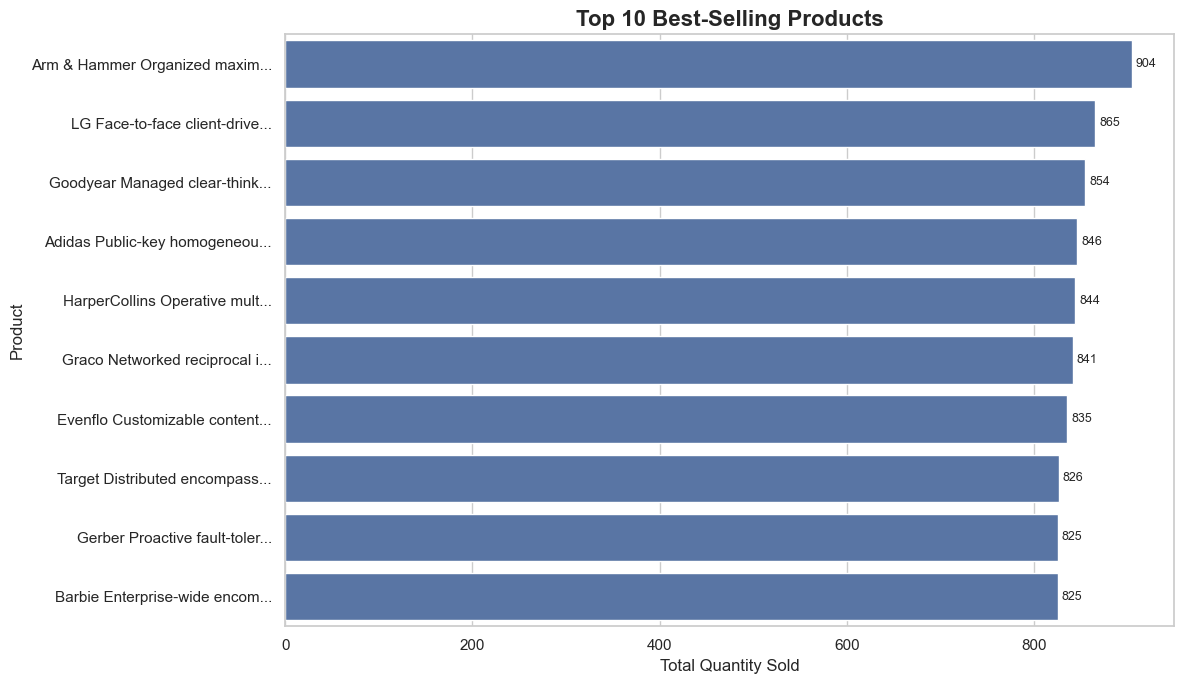

In [24]:
plt.figure(figsize=(12, 7))

plot_data = top_products.copy()
plot_data["short_name"] = (
    plot_data["product_name"].str.slice(0, 28) + "..."
)

ax = sns.barplot(
    data=plot_data,
    x="total_quantity_sold",
    y="short_name"
)

plt.title("Top 10 Best-Selling Products", fontsize=16, fontweight="bold")
plt.xlabel("Total Quantity Sold", fontsize=12)
plt.ylabel("Product", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:
### Key Findings
- The top-selling product was PROD-000839, with 904 units sold.
- PROD-000003 ranked second, with 865 units sold.
- Baby & Kids appeared three times in the top 10 products.
- The top 10 products vary in both sales revenue and profit, showing that the most frequently sold product is not necessarily the most profitable.

### Business Recommendation
The business should maintain adequate stock for high-demand products and separately monitor product profitability before deciding which products to prioritize.


In [ ]:
## Question 5: How Do Sales Change Month by Month?

### Business Question
How do monthly sales change over time?

### Objective
To identify monthly sales patterns and understand changes in sales over the analyzed period.

### SQL Analysis
Orders will be grouped by year and month to calculate total monthly sales and profit.

### Key Findings
To be added after analyzing the results.


In [25]:
query = """
SELECT
    DATE_FORMAT(
        STR_TO_DATE(order_date, '%Y-%m-%d'),
        '%Y-%m'
    ) AS sales_month,
    ROUND(SUM(CAST(net_sales AS DECIMAL(15,2))), 2) AS total_sales,
    ROUND(SUM(CAST(profit AS DECIMAL(15,2))), 2) AS total_profit
FROM ecommerce_sales_customer_analytics_150k
GROUP BY sales_month
ORDER BY sales_month;
"""

monthly_sales = pd.read_sql(query, conn)
display(monthly_sales.head(10))
print("Total months analyzed:", len(monthly_sales))


C:\Users\surbh\AppData\Local\Temp\ipykernel_33724\2124817612.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly_sales = pd.read_sql(query, conn)


,sales_month,total_sales,total_profit
0,2021-01,2374415.22,1129764.43
1,2021-02,1905413.15,900452.55
2,2021-03,2753256.18,1298951.77
3,2021-04,2469384.78,1178381.90
4,2021-05,2546555.37,1219361.44
5,2021-06,2710208.64,1292627.89
6,2021-07,2894416.72,1143965.61
7,2021-08,3220659.48,1526095.90
8,2021-09,2720931.59,1224683.15
9,2021-10,2991778.76,1413407.38


Total months analyzed: 60


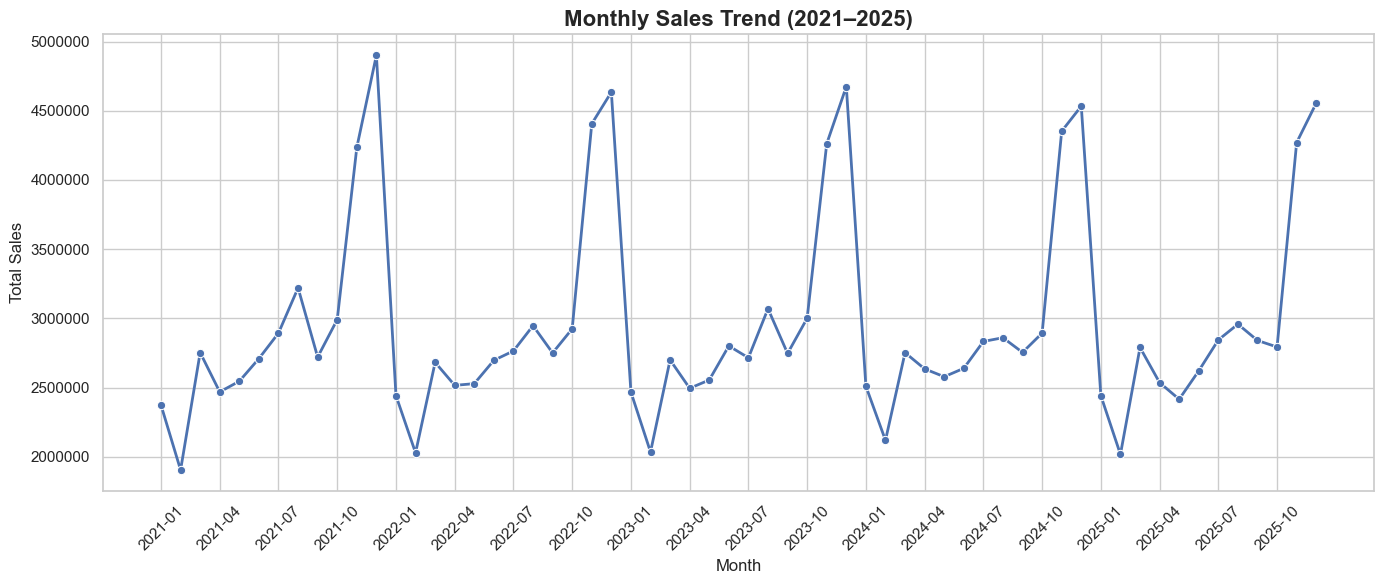

In [26]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="sales_month",
    y="total_sales",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend (2021–2025)", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(
    ticks=range(0, len(monthly_sales), 3),
    labels=monthly_sales["sales_month"].iloc[::3],
    rotation=45
)

plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


In [ ]:
### Key Findings
- The dataset contains 60 months of sales data from January 2021 to December 2025.
- Monthly sales fluctuate rather than remaining constant.
- March 2021 recorded approximately 2.75 million in sales.
- August 2021 recorded approximately 3.22 million in sales, higher than the other months shown in the sample.

### Business